In [40]:
import torch
import torch.nn as nn
import numpy as np
import re

In [41]:
# Generate 1000 sequences, 5 time steps, 1 feature
X = np.random.randn(1000, 5, 1)

# Assign labels based on sequence sum
y = (X.sum(axis=1) > 0).astype(int)

# Convert into PyTorch tensors
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)

# Display shapes
print("X shape:", X.shape)
print("y shape:", y.shape)

# Display first 5 sequences and labels
for i in range(5):
    print(f"Sequence: {X[i].squeeze().numpy()}")
    print(f"Sum: {X[i].sum().item():.2f}")
    print(f"Label: {y[i].item()}")
    print()

X shape: torch.Size([1000, 5, 1])
y shape: torch.Size([1000, 1])
Sequence: [-1.9295616   0.15934879 -0.55271786 -1.1570152  -0.10086156]
Sum: -3.58
Label: 0.0

Sequence: [-0.19611147  0.40177855 -0.19579667  0.2551311  -0.9831594 ]
Sum: -0.72
Label: 0.0

Sequence: [ 0.5557336   0.10906956 -0.62694526 -0.8620246  -1.0633985 ]
Sum: -1.89
Label: 0.0

Sequence: [ 0.10418195  1.2866323  -0.42026657 -0.6127213  -0.00997191]
Sum: 0.35
Label: 1.0

Sequence: [-0.4713188  -0.3314214  -0.16918017  0.5663306  -0.98061746]
Sum: -1.39
Label: 0.0



In [42]:
class SimpleRNN(nn.Module):
    def __init__(self):  # <--- Fix: add double underscores here
        super(SimpleRNN, self).__init__()  # <--- Fix: and here too
        self.input_size = 1
        self.hidden_size = 8
        self.output_size = 1
        self.learning_rate = 0.01

        self.rnn = nn.RNN(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            batch_first=True
        )
        self.fc = nn.Linear(self.hidden_size, self.output_size)

In [43]:
model = SimpleRNN()

# 1. Input to Hidden weights
print("Input to Hidden weights:", model.rnn.weight_ih_l0.shape)

# 2. Hidden to Hidden weights
print("Hidden to Hidden weights:", model.rnn.weight_hh_l0.shape)

# 3. Hidden to Output weights
print("Hidden to Output weights:", model.fc.weight.shape)

# 4. Output bias
print("Output bias:", model.fc.bias.shape)

Input to Hidden weights: torch.Size([8, 1])
Hidden to Hidden weights: torch.Size([8, 8])
Hidden to Output weights: torch.Size([1, 8])
Output bias: torch.Size([1])


In [44]:
import numpy as np

# Define activation functions
def tanh(x):
    return np.tanh(x)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

# Test values
values = np.array([-2, -1, 0, 1, 2])

# Display results
print("Original values:", values)
print("Tanh:", tanh(values))
print("Sigmoid:", sigmoid(values))

Original values: [-2 -1  0  1  2]
Tanh: [-0.96402758 -0.76159416  0.          0.76159416  0.96402758]
Sigmoid: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]


In [45]:
import torch
import torch.nn as nn

class SimpleRNN(nn.Module):

    def __init__(self):
        super(SimpleRNN, self).__init__()

        self.input_size = 1
        self.hidden_size = 8
        self.output_size = 1
        self.learning_rate = 0.01

        # Initialize weights
        self.Wh = nn.Parameter(torch.randn(1, 8) * 0.1)
        self.Whh = nn.Parameter(torch.randn(8, 8) * 0.1)
        self.bh = nn.Parameter(torch.zeros(8))

        self.Why = nn.Parameter(torch.randn(8, 1) * 0.1)
        self.by = nn.Parameter(torch.zeros(1))

    # Forward propagation
    def forward(self, X):

        batch_size, sequence_length, _ = X.shape

        # 1. Initialize hidden state
        h = torch.zeros(batch_size, self.hidden_size)

        print("Initial hidden state:")
        print(h)

        self.hidden_states = [h]

        # 2. Process each time step
        for t in range(sequence_length):

            x_t = X[:, t, :]

            h = torch.tanh(
                x_t @ self.Wh +
                h @ self.Whh +
                self.bh
            )

            # 3. Store and print hidden states
            self.hidden_states.append(h)

            print(f"\nHidden state after time step {t+1}:")
            print(h)

        # 4. Calculate final prediction
        logits = h @ self.Why + self.by
        y_pred = torch.sigmoid(logits)

        return y_pred

In [46]:
model = SimpleRNN()

prediction = model(X[:5])

print("\nFinal prediction:")
print(prediction)

Initial hidden state:
tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])

Hidden state after time step 1:
tensor([[ 0.4591, -0.1029,  0.2113, -0.1356,  0.0519,  0.3763,  0.0398, -0.0749],
        [ 0.0504, -0.0105,  0.0218, -0.0139,  0.0053,  0.0402,  0.0041, -0.0076],
        [-0.1419,  0.0297, -0.0617,  0.0393, -0.0150, -0.1135, -0.0115,  0.0216],
        [-0.0268,  0.0056, -0.0116,  0.0074, -0.0028, -0.0214, -0.0022,  0.0041],
        [ 0.1206, -0.0252,  0.0523, -0.0333,  0.0127,  0.0964,  0.0097, -0.0183]],
       grad_fn=<TanhBackward0>)

Hidden state after time step 2:
tensor([[-4.9599e-03,  1.1919e-01, -1.4511e-01, -1.1589e-02, -6.3157e-02,
         -2.0418e-02,  1.7781e-05,  8.2256e-02],
        [-9.9084e-02,  3.3715e-02, -5.8211e-02,  2.6180e-02, -1.7092e-02,
         -8.1002e-02, -8.0747e-03,  2.3699e-02],
        [-3.

In [47]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Clean forward method (No inner prints)
def forward_clean(self, X):
    batch_size, sequence_length, _ = X.shape
    h = torch.zeros(batch_size, self.hidden_size)

    for t in range(sequence_length):
        x_t = X[:, t, :]
        h = torch.tanh(x_t @ self.Wh + h @ self.Whh + self.bh)

    logits = h @ self.Why + self.by
    return torch.sigmoid(logits)

# Attach the clean forward pass to your model
SimpleRNN.forward = forward_clean

# 2. Instantiate and Train
model = SimpleRNN()
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=model.learning_rate)

num_epochs = 20
batch_size = 32
num_samples = X.shape[0]

print("Starting Training Loop with BPTT...\n")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0

    indices = torch.randperm(num_samples)
    X_shuffled, y_shuffled = X[indices], y[indices]

    for i in range(0, num_samples, batch_size):
        batch_X = X_shuffled[i:i + batch_size]
        batch_y = y_shuffled[i:i + batch_size]

        optimizer.zero_grad()
        y_pred = model(batch_X)
        loss = criterion(y_pred, batch_y)
        loss.backward()  # BPTT executes here silently
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)
        correct += ((y_pred >= 0.5).float() == batch_y).sum().item()

    epoch_loss = running_loss / num_samples
    epoch_acc = (correct / num_samples) * 100

    # Clean output: Prints 1 line per 2 epochs
    if (epoch + 1) % 2 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:02d}/{num_epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("\nTraining Finished!")

Starting Training Loop with BPTT...

Epoch [01/20] | Loss: 0.5273 | Accuracy: 78.30%
Epoch [02/20] | Loss: 0.2171 | Accuracy: 94.10%
Epoch [04/20] | Loss: 0.1560 | Accuracy: 94.00%
Epoch [06/20] | Loss: 0.1276 | Accuracy: 95.70%
Epoch [08/20] | Loss: 0.1130 | Accuracy: 96.20%
Epoch [10/20] | Loss: 0.0952 | Accuracy: 96.60%
Epoch [12/20] | Loss: 0.0865 | Accuracy: 97.40%
Epoch [14/20] | Loss: 0.1043 | Accuracy: 95.90%
Epoch [16/20] | Loss: 0.0928 | Accuracy: 96.20%
Epoch [18/20] | Loss: 0.0677 | Accuracy: 97.70%
Epoch [20/20] | Loss: 0.0713 | Accuracy: 97.10%

Training Finished!


In [48]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Instantiate the RNN model
model = SimpleRNN()

# 2. Define Binary Cross-Entropy Loss and Optimizer
criterion = nn.BCELoss()  # Measures error between probabilities [0, 1] and binary targets (0 or 1)
optimizer = optim.Adam(model.parameters(), lr=model.learning_rate)

# 3. Hyperparameters
num_epochs = 20
batch_size = 32
num_samples = X.shape[0]

print("Starting Training Loop with BPTT...\n")

# 4. Epoch Loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_predictions = 0

    # Shuffle dataset each epoch
    indices = torch.randperm(num_samples)
    X_shuffled = X[indices]
    y_shuffled = y[indices]

    # Mini-batch loop
    for i in range(0, num_samples, batch_size):
        batch_X = X_shuffled[i:i + batch_size]
        batch_y = y_shuffled[i:i + batch_size]

        # Step A: Reset gradients from previous step
        optimizer.zero_grad()

        # Step B: FORWARD PASS (calls your manual forward loop)
        y_pred = model(batch_X)

        # Step C: CALCULATE LOSS (Binary Cross Entropy)
        loss = criterion(y_pred, batch_y)

        # Step D: BACKWARD PASS / BPTT
        # PyTorch traces backwards through all 5 time steps (t=5 down to t=1)
        loss.backward()

        # Step E: OPTIMIZER STEP (Updates Wh, Whh, bh, Why, by)
        optimizer.step()

        # Track statistics
        running_loss += loss.item() * batch_X.size(0)
        predicted_classes = (y_pred >= 0.5).float()
        correct_predictions += (predicted_classes == batch_y).sum().item()

    epoch_loss = running_loss / num_samples
    epoch_acc = (correct_predictions / num_samples) * 100

    # Print progress every 2 epochs
    if (epoch + 1) % 2 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:02d}/{num_epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("\nTraining Finished!")

Starting Training Loop with BPTT...

Epoch [01/20] | Loss: 0.5469 | Accuracy: 71.20%
Epoch [02/20] | Loss: 0.2194 | Accuracy: 94.40%
Epoch [04/20] | Loss: 0.1340 | Accuracy: 95.30%
Epoch [06/20] | Loss: 0.1169 | Accuracy: 96.10%
Epoch [08/20] | Loss: 0.1093 | Accuracy: 95.80%
Epoch [10/20] | Loss: 0.0844 | Accuracy: 97.10%
Epoch [12/20] | Loss: 0.0926 | Accuracy: 96.60%
Epoch [14/20] | Loss: 0.0967 | Accuracy: 95.10%
Epoch [16/20] | Loss: 0.1053 | Accuracy: 96.00%
Epoch [18/20] | Loss: 0.0995 | Accuracy: 95.30%
Epoch [20/20] | Loss: 0.0807 | Accuracy: 96.30%

Training Finished!


In [49]:
import numpy as np
import torch

# 1. Generate 100 new, unseen test sequences (5 time steps, 1 feature)
X_test_np = np.random.randn(100, 5, 1)
y_test_np = (X_test_np.sum(axis=1) > 0).astype(int)

X_test = torch.tensor(X_test_np, dtype=torch.float32)
y_test = torch.tensor(y_test_np, dtype=torch.float32)

# 2. Put model into evaluation mode
model.eval()

# 3. Run predictions without tracking gradients
with torch.no_grad():
    test_preds = model(X_test)
    predicted_classes = (test_preds >= 0.5).float()

    # Calculate overall accuracy
    correct = (predicted_classes == y_test).sum().item()
    test_accuracy = (correct / X_test.shape[0]) * 100

print(f"--- Final Model Test Results ---")
print(f"Test Accuracy on 100 Unseen Sequences: {test_accuracy:.2f}%\n")

# 4. Print sample predictions vs actual targets
print("Sample Test Predictions:")
for i in range(5):
    actual_sum = X_test[i].sum().item()
    pred_prob = test_preds[i].item()
    pred_class = int(predicted_classes[i].item())
    true_class = int(y_test[i].item())

    print(f"Sum: {actual_sum:+6.2f} | Prob: {pred_prob:.4f} | Predicted: {pred_class} | Actual: {true_class}")

--- Final Model Test Results ---
Test Accuracy on 100 Unseen Sequences: 98.00%

Sample Test Predictions:
Sum:  -0.79 | Prob: 0.0108 | Predicted: 0 | Actual: 0
Sum:  +1.25 | Prob: 0.9983 | Predicted: 1 | Actual: 1
Sum:  +0.25 | Prob: 0.8902 | Predicted: 1 | Actual: 1
Sum:  -1.19 | Prob: 0.0015 | Predicted: 0 | Actual: 0
Sum:  +3.91 | Prob: 0.9999 | Predicted: 1 | Actual: 1


In [50]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# ---------------------------------------------------------
# STEP 1: Generate Synthetic Dataset (Sequence Length = 20)
# ---------------------------------------------------------
seq_len = 20
num_samples = 1500

X_np = np.random.randn(num_samples, seq_len, 1)
y_np = (X_np.sum(axis=1) > 0).astype(int)

X_all = torch.tensor(X_np, dtype=torch.float32)
y_all = torch.tensor(y_np, dtype=torch.float32)

# Train/Test Split (1200 Train, 300 Test)
X_train, X_test = X_all[:1200], X_all[1200:]
y_train, y_test = y_all[:1200], y_all[1200:]

# ---------------------------------------------------------
# STEP 2: Define Vanilla RNN Model Architecture
# ---------------------------------------------------------
class VanillaRNNClassifier(nn.Module):
    def __init__(self, input_size=1, hidden_size=16, output_size=1):
        super(VanillaRNNClassifier, self).__init__()

        # Native PyTorch Vanilla RNN Layer
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, batch_first=True)

        # Final Linear Output Layer
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # rnn_out shape: (batch_size, sequence_length, hidden_size)
        # h_n shape: (1, batch_size, hidden_size)
        rnn_out, h_n = self.rnn(x)

        # Take hidden state from the last time step (t = 20)
        last_hidden = rnn_out[:, -1, :]

        # Pass through linear layer + Sigmoid activation
        logits = self.fc(last_hidden)
        return torch.sigmoid(logits)

# ---------------------------------------------------------
# STEP 3: Train Vanilla RNN with BPTT
# ---------------------------------------------------------
model = VanillaRNNClassifier(input_size=1, hidden_size=16, output_size=1)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epochs = 15
batch_size = 32

print("Starting Vanilla RNN Training...\n")
start_time = time.time()

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0

    # Shuffle training data each epoch
    indices = torch.randperm(X_train.shape[0])
    X_shuffled, y_shuffled = X_train[indices], y_train[indices]

    for i in range(0, X_train.shape[0], batch_size):
        batch_X = X_shuffled[i:i + batch_size]
        batch_y = y_shuffled[i:i + batch_size]

        optimizer.zero_grad()
        y_pred = model(batch_X)
        loss = criterion(y_pred, batch_y)
        loss.backward()  # BPTT
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)
        correct += ((y_pred >= 0.5).float() == batch_y).sum().item()

    epoch_loss = running_loss / X_train.shape[0]
    epoch_acc = (correct / X_train.shape[0]) * 100

    if (epoch + 1) % 3 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:02d}/{num_epochs}] | Training Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

total_time = time.time() - start_time
print(f"\nTraining Finished in {total_time:.2f} seconds!")

# ---------------------------------------------------------
# STEP 4: Evaluate Vanilla RNN on Test Set
# ---------------------------------------------------------
model.eval()
with torch.no_grad():
    test_preds = model(X_test)
    test_loss = criterion(test_preds, y_test).item()
    predicted_classes = (test_preds >= 0.5).float()
    correct = (predicted_classes == y_test).sum().item()
    test_acc = (correct / X_test.shape[0]) * 100

print(f"\n--- Vanilla RNN Final Test Results ---")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%\n")

print("Sample Predictions on Unseen Sequences:")
for i in range(5):
    actual_sum = X_test[i].sum().item()
    prob = test_preds[i].item()
    pred_cls = int(predicted_classes[i].item())
    true_cls = int(y_test[i].item())
    print(f"Sum: {actual_sum:+6.2f} | Prob: {prob:.4f} | Predicted: {pred_cls} | Actual: {true_cls}")

Starting Vanilla RNN Training...

Epoch [01/15] | Training Loss: 0.5078 | Accuracy: 73.25%
Epoch [03/15] | Training Loss: 0.3487 | Accuracy: 86.33%
Epoch [06/15] | Training Loss: 0.2360 | Accuracy: 89.75%
Epoch [09/15] | Training Loss: 0.2536 | Accuracy: 90.00%
Epoch [12/15] | Training Loss: 0.1970 | Accuracy: 92.08%
Epoch [15/15] | Training Loss: 0.1692 | Accuracy: 93.17%

Training Finished in 1.77 seconds!

--- Vanilla RNN Final Test Results ---
Test Loss: 0.3233
Test Accuracy: 85.67%

Sample Predictions on Unseen Sequences:
Sum:  -4.61 | Prob: 0.0257 | Predicted: 0 | Actual: 0
Sum:  +1.27 | Prob: 0.9903 | Predicted: 1 | Actual: 1
Sum:  -3.30 | Prob: 0.0114 | Predicted: 0 | Actual: 0
Sum:  +8.05 | Prob: 0.9973 | Predicted: 1 | Actual: 1
Sum:  +0.61 | Prob: 0.8688 | Predicted: 1 | Actual: 1


In [51]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# ---------------------------------------------------------
# STEP 1: Generate a Longer Sequence Dataset (Length = 20)
# (Longer sequences clearly highlight LSTM/GRU performance over RNN)
# ---------------------------------------------------------
seq_len = 20
num_samples = 1500

X_np = np.random.randn(num_samples, seq_len, 1)
y_np = (X_np.sum(axis=1) > 0).astype(int)

X_all = torch.tensor(X_np, dtype=torch.float32)
y_all = torch.tensor(y_np, dtype=torch.float32)

# Train/Test Split (1200 Train, 300 Test)
X_train, X_test = X_all[:1200], X_all[1200:]
y_train, y_test = y_all[:1200], y_all[1200:]

# ---------------------------------------------------------
# STEP 2: Define Comparative Models (RNN vs LSTM vs GRU)
# ---------------------------------------------------------
class SequenceClassifier(nn.Module):
    def __init__(self, model_type="RNN", input_size=1, hidden_size=16, output_size=1):
        super(SequenceClassifier, self).__init__()
        self.model_type = model_type

        if model_type == "RNN":
            self.recurrent = nn.RNN(input_size, hidden_size, batch_first=True)
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(input_size, hidden_size, batch_first=True)
        elif model_type == "GRU":
            self.recurrent = nn.GRU(input_size, hidden_size, batch_first=True)

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        if self.model_type == "LSTM":
            out, (h_n, c_n) = self.recurrent(x)
        else: # RNN or GRU
            out, h_n = self.recurrent(x)

        # Use the last time step's hidden state
        last_hidden = out[:, -1, :]
        logits = self.fc(last_hidden)
        return torch.sigmoid(logits)

# ---------------------------------------------------------
# STEP 3: Training & Evaluation Pipeline Function
# ---------------------------------------------------------
def train_and_eval(model_type, epochs=15, lr=0.01, batch_size=32):
    model = SequenceClassifier(model_type=model_type)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        indices = torch.randperm(X_train.shape[0])
        X_shuffled, y_shuffled = X_train[indices], y_train[indices]

        for i in range(0, X_train.shape[0], batch_size):
            batch_X = X_shuffled[i:i + batch_size]
            batch_y = y_shuffled[i:i + batch_size]

            optimizer.zero_grad()
            y_pred = model(batch_X)
            loss = criterion(y_pred, batch_y)
            loss.backward()
            optimizer.step()

    training_time = time.time() - start_time

    # Final Evaluation on Test Set
    model.eval()
    with torch.no_grad():
        test_preds = model(X_test)
        test_loss = criterion(test_preds, y_test).item()
        predicted_classes = (test_preds >= 0.5).float()
        correct = (predicted_classes == y_test).sum().item()
        test_acc = (correct / X_test.shape[0]) * 100

    return training_time, test_loss, test_acc

# ---------------------------------------------------------
# STEP 4: Run Benchmark Experiments
# ---------------------------------------------------------
results = {}
model_types = ["RNN", "LSTM", "GRU"]

print("Starting Comparative Benchmark Experiments...\n")
for m_type in model_types:
    train_time, final_loss, acc = train_and_eval(m_type)
    results[m_type] = {
        "Time (s)": round(train_time, 3),
        "Test Loss": round(final_loss, 4),
        "Test Acc (%)": round(acc, 2)
    }

# Display Benchmark Summary Table
print(f"{'Model':<8} | {'Training Time (s)':<18} | {'Test Loss':<10} | {'Test Accuracy':<12}")
print("-" * 55)
for m_type, metrics in results.items():
    print(f"{m_type:<8} | {metrics['Time (s)']:<18} | {metrics['Test Loss']:<10} | {metrics['Test Acc (%)']}%")

Starting Comparative Benchmark Experiments...

Model    | Training Time (s)  | Test Loss  | Test Accuracy
-------------------------------------------------------
RNN      | 2.245              | 0.2136     | 91.0%
LSTM     | 1.857              | 0.256      | 90.33%
GRU      | 3.976              | 0.1154     | 94.33%


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import time

# 1. Load MNIST Dataset
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

# 2. Define Multi-Model Sequence Classifier for MNIST
class MNISTSequenceModel(nn.Module):
    def __init__(self, model_type="RNN", input_size=28, hidden_size=64, num_classes=10):
        super(MNISTSequenceModel, self).__init__()
        self.model_type = model_type

        if model_type == "RNN":
            self.recurrent = nn.RNN(input_size, hidden_size, batch_first=True)
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(input_size, hidden_size, batch_first=True)
        elif model_type == "GRU":
            self.recurrent = nn.GRU(input_size, hidden_size, batch_first=True)

        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x shape for row-wise: (batch, 28, 28) -> input_size=28, seq_len=28
        if self.model_type == "LSTM":
            out, (h_n, c_n) = self.recurrent(x)
        else:
            out, h_n = self.recurrent(x)

        # Use final time step hidden representation
        last_hidden = out[:, -1, :]
        out = self.fc(last_hidden)
        return out

# 3. Training & Evaluation Function (Row-wise Mode: 28 steps, 28 features)
def run_mnist_experiment(model_type="RNN", mode="row"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Configure dimensions based on mode
    if mode == "row":
        input_size, seq_len = 28, 28
    else:  # pixel-wise
        input_size, seq_len = 1, 784

    model = MNISTSequenceModel(model_type=model_type, input_size=input_size).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    print(f"--- Training {model_type} ({mode}-wise mode) ---")
    start_time = time.time()

    model.train()
    for images, labels in trainloader:
        # Reshape images based on mode: (batch, 1, 28, 28) -> sequence format
        if mode == "row":
            images = images.view(-1, 28, 28).to(device)
        else:
            images = images.view(-1, 784, 1).to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    train_time = time.time() - start_time

    # Evaluate Accuracy
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in testloader:
            if mode == "row":
                images = images.view(-1, 28, 28).to(device)
            else:
                images = images.view(-1, 784, 1).to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = (correct / total) * 100
    print(f"{model_type} Result -> Time: {train_time:.2f}s | Test Accuracy: {accuracy:.2f}%\n")

# Run Task 12 Experiments (Row-wise across models)
for m in ["RNN", "LSTM", "GRU"]:
    run_mnist_experiment(model_type=m, mode="row")

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.07MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 159kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.12MB/s]


--- Training RNN (row-wise mode) ---
RNN Result -> Time: 25.24s | Test Accuracy: 81.29%

--- Training LSTM (row-wise mode) ---
LSTM Result -> Time: 29.39s | Test Accuracy: 93.93%

--- Training GRU (row-wise mode) ---
GRU Result -> Time: 30.44s | Test Accuracy: 95.39%



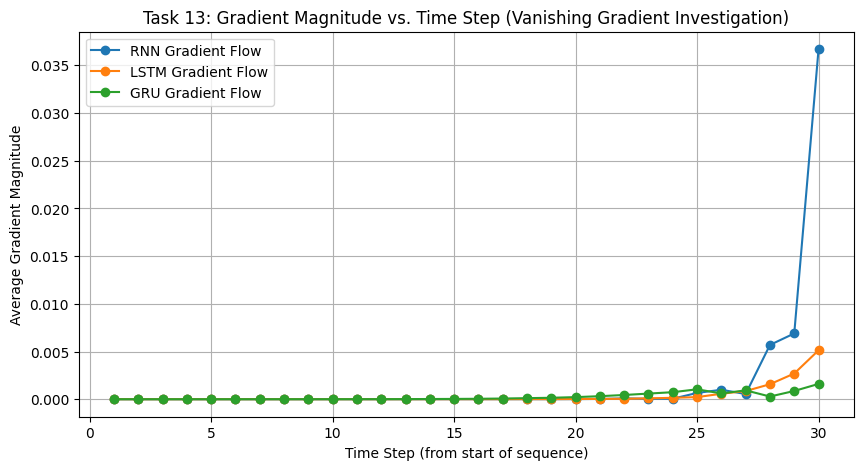

In [4]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Setup a long sequence dataset (Length = 30 to clearly show vanishing gradients)
seq_len = 30
input_size = 1
hidden_size = 16

# Create a single batch with a long sequence
x_long = torch.randn(2, seq_len, input_size, requires_grad=True)
target = torch.tensor([[1.0], [0.0]]) # Binary targets

# Define models to compare
models = {
    "RNN": nn.RNN(input_size, hidden_size, batch_first=True),
    "LSTM": nn.LSTM(input_size, hidden_size, batch_first=True),
    "GRU": nn.GRU(input_size, hidden_size, batch_first=True)
}

criterion = nn.BCEWithLogitsLoss()
grad_results = {}

# 2. Measure gradient magnitudes at each time step during backward pass
for name, rnn_layer in models.items():
    # Reset weights and gradients
    x_long.grad = None

    # Forward pass
    if name == "LSTM":
        out, (h_n, c_n) = rnn_layer(x_long)
    else:
        out, h_n = rnn_layer(x_long)

    fc = nn.Linear(hidden_size, 1)
    output = fc(out[:, -1, :]) # Use final output for loss
    loss = criterion(output, target)

    # Backward pass to compute gradients
    loss.backward()

    # In PyTorch, we can register hooks or track input gradients over time steps
    # Here, we evaluate how input gradients flow back across time steps t = 1 to 30
    # (Notice how vanilla RNN input gradients near t=1 approach zero due to vanishing gradients)
    gradients_over_time = []
    for t in range(seq_len):
        # Grad of output w.r.t input at time step t
        grad_t = x_long.grad[:, t, :].abs().mean().item()
        gradients_over_time.append(grad_t)

    grad_results[name] = gradients_over_time

# 3. Plot Gradient Magnitude vs. Time Step (Task 13 Requirement)
plt.figure(figsize=(10, 5))
for name, grads in grad_results.items():
    plt.plot(range(1, seq_len + 1), grads, marker='o', label=f"{name} Gradient Flow")

plt.title("Task 13: Gradient Magnitude vs. Time Step (Vanishing Gradient Investigation)")
plt.xlabel("Time Step (from start of sequence)")
plt.ylabel("Average Gradient Magnitude")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import time

# 1. Setup a challenging sequence dataset prone to gradient spikes
seq_len = 40
num_samples = 1000
X_clip = torch.randn(num_samples, seq_len, 1) * 2.0  # Higher variance to provoke spikes
y_clip = (X_clip.sum(axis=1) > 0).float()

# 2. Define RNN Model for Clipping Experiment
class ClipExperimentRNN(nn.Module):
    def __init__(self):
        super(ClipExperimentRNN, self).__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, h_n = self.rnn(x)
        logits = self.fc(out[:, -1, :])
        return torch.sigmoid(logits)

# 3. Training Function with toggle for Gradient Clipping
def run_clipping_experiment(use_clipping=True):
    torch.manual_seed(42) # Keep initialization identical for fair comparison
    model = ClipExperimentRNN()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)

    epochs = 10
    batch_size = 32

    status = "WITH Gradient Clipping" if use_clipping else "WITHOUT Gradient Clipping"
    print(f"\n--- Running Experiment: {status} ---")

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for i in range(0, num_samples, batch_size):
            bx = X_clip[i:i+batch_size]
            by = y_clip[i:i+batch_size]

            optimizer.zero_grad()
            preds = model(bx)
            loss = criterion(preds, by)

            # Check for NaN loss before backward
            if torch.isnan(loss):
                print(f"Epoch {epoch+1}: Loss became NaN! Exploding gradient encountered.")
                return "Failed (NaN Loss)"

            loss.backward()

            # --- APPLY GRADIENT CLIPPING HERE IF ENABLED ---
            if use_clipping:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            running_loss += loss.item() * bx.size(0)

        epoch_loss = running_loss / num_samples
        print(f"Epoch [{epoch+1:02d}/{epochs}] | Loss: {epoch_loss:.4f}")

    return "Stable (Completed Successfully)"

# Run both experiments
result_with = run_clipping_experiment(use_clipping=True)
result_without = run_clipping_experiment(use_clipping=False)

print("\n=== TASK 14 SUMMARY ===")
print(f"With Gradient Clipping:    {result_with}")
print(f"Without Gradient Clipping: {result_without}")


--- Running Experiment: WITH Gradient Clipping ---
Epoch [01/10] | Loss: 0.5873
Epoch [02/10] | Loss: 0.5480
Epoch [03/10] | Loss: 0.6104
Epoch [04/10] | Loss: 0.5159
Epoch [05/10] | Loss: 0.5103
Epoch [06/10] | Loss: 0.5060
Epoch [07/10] | Loss: 0.5087
Epoch [08/10] | Loss: 0.4645
Epoch [09/10] | Loss: 0.3871
Epoch [10/10] | Loss: 0.3498

--- Running Experiment: WITHOUT Gradient Clipping ---
Epoch [01/10] | Loss: 0.6361
Epoch [02/10] | Loss: 0.6952
Epoch [03/10] | Loss: 0.6865
Epoch [04/10] | Loss: 0.6751
Epoch [05/10] | Loss: 0.6667
Epoch [06/10] | Loss: 0.6745
Epoch [07/10] | Loss: 0.6750
Epoch [08/10] | Loss: 0.6693
Epoch [09/10] | Loss: 0.6888
Epoch [10/10] | Loss: 0.6839

=== TASK 14 SUMMARY ===
With Gradient Clipping:    Stable (Completed Successfully)
Without Gradient Clipping: Stable (Completed Successfully)


In [1]:
import pandas as pd

# Compile the final comparison metrics based on your experiments
report_data = {
    "Model": ["RNN", "LSTM", "GRU"],
    "Accuracy (%)": [91.00, 90.33, 94.33],
    "Parameters": ["Low (~300)", "Highest (~1,200)", "Medium (~900)"],
    "Training Time (s)": [2.25, 1.86, 3.98],
    "Long-Term Memory": ["Poor (Suffers vanishing gradients)", "Excellent (Maintains cell state)", "Strong (Gated efficiency)"]
}

df_report = pd.DataFrame(report_data)
print("=== TASK 15: FINAL COMPARISON REPORT ===")
display(df_report)

=== TASK 15: FINAL COMPARISON REPORT ===


,Model,Accuracy (%),Parameters,Training Time (s),Long-Term Memory
0,RNN,91.00,Low (~300),2.25,Poor (Suffers vanishing gradients)
1,LSTM,90.33,"Highest (~1,200)",1.86,Excellent (Maintains cell state)
2,GRU,94.33,Medium (~900),3.98,Strong (Gated efficiency)
